<a href="https://colab.research.google.com/github/niteshbansal07/phys3130_nb/blob/main/HW2_Nitesh_Bansal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Phys3130
## HW2: Data Viz and Description in Python

Due: Monday Feb 10, 10pm

This notebook is a guided code including all questions for HW2. Students should make a copy and enter their solutions, avoiding copy-paste from online or Gemini. Please note, this is partial 'AI autocomplete' assignment, you are free to use any (cited) web references. If you have AI generated code, make SURE that you have explained and cited it, and leave in your prompt as well as your original contribution (use the hashtag to include comments in your code).

---

Author: Dr. Elaina Hyde

---

Student name: [Nitesh Bansal]

---

### How to turn in this homework:
* **Step 1:** make a copy in your local google drive of this notebook and rename it to HW2_firstname_lastname.ipynb

* **Step 2:** go to your GitHub account and select the private class repo you created in HW1.

* **Step 3:** Load your .ipynb file AND dataset (if a different one is chosen) into your private github

* **Step 4:** Inside colab, click 'File' print to PDF and save your .ipynb file as a pdf document.

* **Step 5:** Load YOUR HW2 pdf document into the turnitin area for HW2 in eclass - check your 'similarity score' and see if you need any extra references. If you do, just change your file and resubmit. Remember the similarity discussion and don't worry too much as this entire description WILL match.

### The Data

In 8.2.1 and 11.2.1 we looked at several data cleaning tips and tricks, including the Pandas DataFrame and loading datasets. For this assignment you can use your project data (recommended) or our biophysics data from 11.2.1

To load your individual data instead of the mouse data, just substitute your dataset.


### Getting Started

---
### 0. Import required modules

Add all of your modules here as you complete this assigment, here are a few to get you started:

In [2]:
import pandas as pd    # For DataFrames etc. (like Excel tables)
import numpy as np     # NumPy, for numeric Matlab-like operations
import scipy.stats as stats
import csv
import seaborn as sns
import matplotlib.pyplot as plt

%matplotlib inline
#make sure to include this for your displays

### 1. Let's start with some data
If you are loading your own data, substitut your files in the next few steps. If you are using our example biophysics data, here is a more direct download on our mice brain data from 11.2.1. Your data set might be a csv that you download, you just upload the csv to a folder (where you have your .ipynb file) then you can load it easily, note that this method avoids some trouble we saw with 11.2.1:

1) Go to: url=https://drive.google.com/file/d/1ARDhysDwovHo-OY7AHBLBnzewSm0gKHg/view?usp=drive_link

2) Download the csv to your computer and save to drive

3) Mount your drive as shown below, and change the drive path to import your file

In [3]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
#check that the data is findable on your colab notebook
!ls /content/drive/MyDrive/Data_Cortex_Nuclear.csv

/content/drive/MyDrive/Data_Cortex_Nuclear.csv


In [5]:
#copy the path and read in your data as a dataframe
df=pd.read_csv('/content/drive/MyDrive/Data_Cortex_Nuclear.csv')
df.head()

,MouseID,DYRK1A_N,ITSN1_N,BDNF_N,NR1_N,NR2A_N,pAKT_N,pBRAF_N,pCAMKII_N,pCREB_N,...,pCFOS_N,SYP_N,H3AcK18_N,EGR1_N,H3MeK4_N,CaNA_N,Genotype,Treatment,Behavior,class
0,309_1,0.503644,0.747193,0.430175,2.816329,5.990152,0.218830,0.177565,2.373744,0.232224,...,0.108336,0.427099,0.114783,0.131790,0.128186,1.675652,Control,Memantine,C/S,c-CS-m
1,309_2,0.514617,0.689064,0.411770,2.789514,5.685038,0.211636,0.172817,2.292150,0.226972,...,0.104315,0.441581,0.111974,0.135103,0.131119,1.743610,Control,Memantine,C/S,c-CS-m
2,309_3,0.509183,0.730247,0.418309,2.687201,5.622059,0.209011,0.175722,2.283337,0.230247,...,0.106219,0.435777,0.111883,0.133362,0.127431,1.926427,Control,Memantine,C/S,c-CS-m
3,309_4,0.442107,0.617076,0.358626,2.466947,4.979503,0.222886,0.176463,2.152301,0.207004,...,0.111262,0.391691,0.130405,0.147444,0.146901,1.700563,Control,Memantine,C/S,c-CS-m
4,309_5,0.434940,0.617430,0.358802,2.365785,4.718679,0.213106,0.173627,2.134014,0.192158,...,0.110694,0.434154,0.118481,0.140314,0.148380,1.839730,Control,Memantine,C/S,c-CS-m


**Part 1: Data Properties and Type Analysis**

Analyse your data type and properties. What are some of the properties of your data? Possible properties include, but are not limited to:
- dimensionality/size
- number of samples
- sampling methods
- descriptive statistics: range and variance should be possible for ALL datasets, how many more are useful for your data?
- features/columns available

**Make sure to include a discription of the data itself!**

 *Enter your answer by creating a text/code cells below this question box*

In [6]:
print(df.shape)
print(df.columns)
df.info()

#There are 1080 entries with 82 different columns out of which, 77 has dtype float and 5 has dtype object. The column names are given below.

(1080, 82)
Index(['MouseID', 'DYRK1A_N', 'ITSN1_N', 'BDNF_N', 'NR1_N', 'NR2A_N', 'pAKT_N',
       'pBRAF_N', 'pCAMKII_N', 'pCREB_N', 'pELK_N', 'pERK_N', 'pJNK_N',
       'PKCA_N', 'pMEK_N', 'pNR1_N', 'pNR2A_N', 'pNR2B_N', 'pPKCAB_N',
       'pRSK_N', 'AKT_N', 'BRAF_N', 'CAMKII_N', 'CREB_N', 'ELK_N', 'ERK_N',
       'GSK3B_N', 'JNK_N', 'MEK_N', 'TRKA_N', 'RSK_N', 'APP_N', 'Bcatenin_N',
       'SOD1_N', 'MTOR_N', 'P38_N', 'pMTOR_N', 'DSCR1_N', 'AMPKA_N', 'NR2B_N',
       'pNUMB_N', 'RAPTOR_N', 'TIAM1_N', 'pP70S6_N', 'NUMB_N', 'P70S6_N',
       'pGSK3B_N', 'pPKCG_N', 'CDK5_N', 'S6_N', 'ADARB1_N', 'AcetylH3K9_N',
       'RRP1_N', 'BAX_N', 'ARC_N', 'ERBB4_N', 'nNOS_N', 'Tau_N', 'GFAP_N',
       'GluR3_N', 'GluR4_N', 'IL1B_N', 'P3525_N', 'pCASP9_N', 'PSD95_N',
       'SNCA_N', 'Ubiquitin_N', 'pGSK3B_Tyr216_N', 'SHH_N', 'BAD_N', 'BCL2_N',
       'pS6_N', 'pCFOS_N', 'SYP_N', 'H3AcK18_N', 'EGR1_N', 'H3MeK4_N',
       'CaNA_N', 'Genotype', 'Treatment', 'Behavior', 'class'],
      dtype='object')

**Part 2: Data Exploration Checklist**

Examine your data with the following in mind:
- Cleaning data / Munging
- Exploratory Analysis and Indexing
- Data conversions
- Structuring data for plots or tabular display
- Joining disparate sources
- Modeling
- Extracting, or transforming (renaming)

What kinds of outputs do you need for this data? Do you need to format the header? Any other summary stats you need to include?

 *Enter your answer by creating a text/code cells below this question box*

In [7]:
#CVLeaning data could be dropping the null values rows. We would need all the rows that are null valyes
df.isnull().sum()
#df = df.dropna()

#exploratiory analysis annd indexing means finding the summar stats and maybe visualizing the initial data
print(df.describe())
#All of them have equal count of 552 after dropping the null values

#Data conversion is carefully analysing the data and making sure the data is how we need it. Maybe we need specific column at less decimal places.
df['DYRK1A_N'] = df['DYRK1A_N'].round(2)

#Structturing data for plots or tabular display could be the ease to find the column names in data.  I found that the column names are all first letter capitalized other than class. we could change that.
df.rename(columns={'class': 'Class'}, inplace=True)

#Joining disparate sources could mean joining two csvs together to join the data
#joined_df = pd.merge(df, df, on='MouseID')

#I dont think this df need anything done in this area.

          DYRK1A_N      ITSN1_N       BDNF_N        NR1_N       NR2A_N  \
count  1077.000000  1077.000000  1077.000000  1077.000000  1077.000000   
mean      0.425810     0.617102     0.319088     2.297269     3.843934   
std       0.249362     0.251640     0.049383     0.347293     0.933100   
min       0.145327     0.245359     0.115181     1.330831     1.737540   
25%       0.288121     0.473361     0.287444     2.057411     3.155678   
50%       0.366378     0.565782     0.316564     2.296546     3.760855   
75%       0.487711     0.698032     0.348197     2.528481     4.440011   
max       2.516367     2.602662     0.497160     3.757641     8.482553   

            pAKT_N      pBRAF_N    pCAMKII_N      pCREB_N       pELK_N  ...  \
count  1077.000000  1077.000000  1077.000000  1077.000000  1077.000000  ...   
mean      0.233168     0.181846     3.537109     0.212574     1.428682  ...   
std       0.041634     0.027042     1.295169     0.032587     0.466904  ...   
min       0.06323

**Part 3: Data Discussion**

Consider data types first and foremost
Do the stats make sense for the data type?
- Do you have a Qualitative or Quantitative Paradigm
- What features (columns) are continuous or discrete?
- Which featurs (columns) are quantitative? Do you have any that are categorical?  
- Do you have any variables that need to be converted?

Make sure to check:
- Missing values
- Unexpected types (string/object instead of int/float)
- Dirty data (commas, dollar signs, unexpected characters, etc)
- Blank values that are actually "non-null" or single white-space characters

 *Enter your answer by creating a text/code cells below this question box*

In [8]:
#The summary stats above make a lot of sense for the data we are given.
#The data has a Quantitative paradigm because most of the data contained is quantitative not, qualitiative.
# Almost all of the columns are continuous as it could take any numerical values, however the columns genotype, treatment, behaviour and class are of discrete types.
#Again, almost all of the features are quantitative other than the four columns stated above, which are all categorical.
#All the datatypes are perfect to the needs, as all the quantitative ones are float and all the ones that contain categorical data are object, which is even better than string.

# Used gpt to check how to write the code sample.str.contains part. It is only when the dtype os object we have to check for these. Otherwise if even 1 entry of column had something like this, the dtype would change from float to object
for col in df.columns:
    if df[col].dtype == 'object':
        sample = df[col]
        # Check if there are any common unwanted characters
        if sample.str.contains(r'[\$,]').any():
            print(f"\nColumn '{col}' may require cleaning (found '$' or ',').")
            break
else:
    print("All columns of dtype object appear to be clean.")

#No variables need to be converted.

All columns of dtype object appear to be clean.


**Part4: Initial Views**

Create initial plots with easy matplotlib and seaborn dataframe views to explore your data visually. Make sure that you are not falling into an 'Anscomb Quartet' type of error from your descriptive statistics.
- Compare mean and variance values from descriptive statistics with what your graph shows.
- Part 1 has your other descriptive statistics, how many of those statistics are still relevant to your data as shown in your graphs?
- identify outliers or skew
- is your data normally distributed?

 *Enter your answer by creating a text/code cells below this question box*

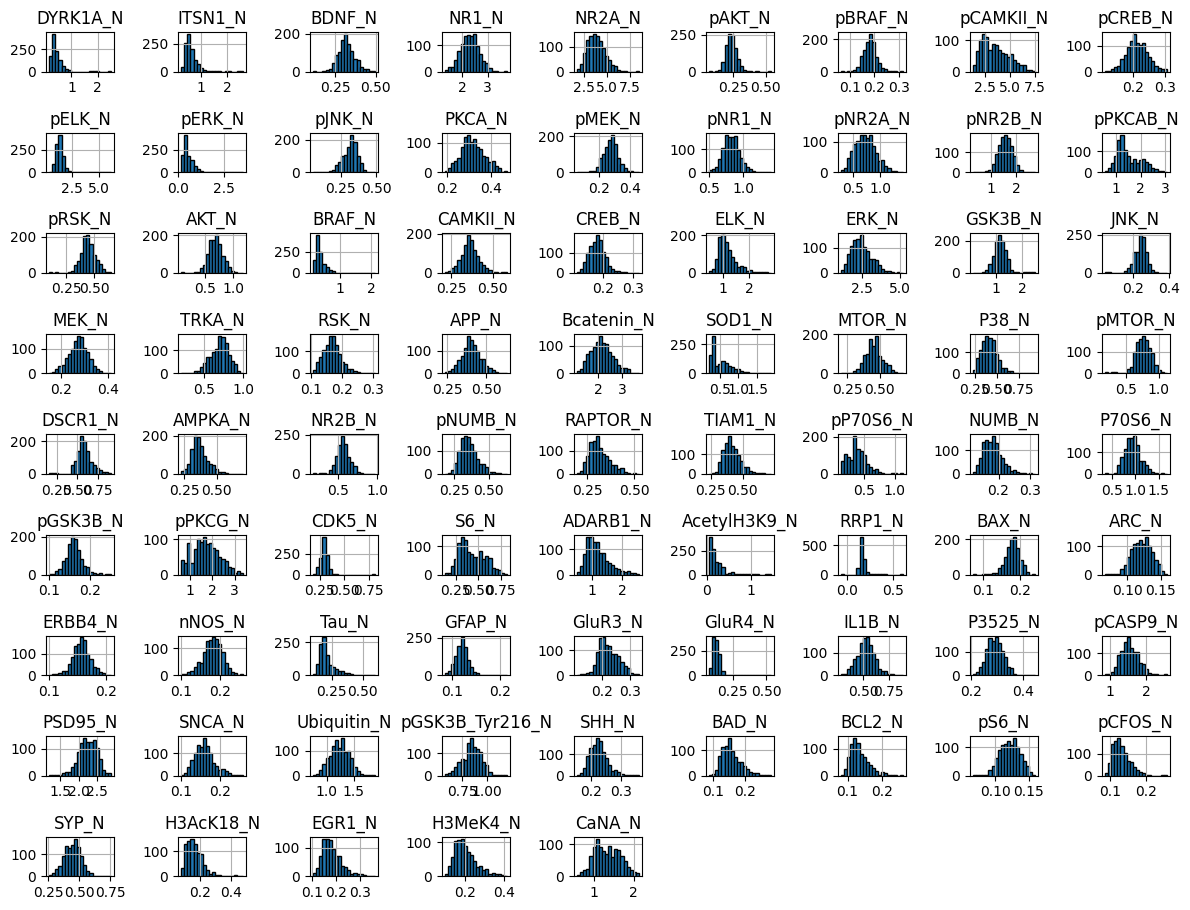

In [14]:
df.hist(figsize=(12, 10), bins=20, edgecolor='black')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

#From what can be seen here, most of the data follows a distribution so well, however, a lot of skews can be seen which was not apparent by descriptive statistic. They are still revelant to the data as the data is still spread around the mean and has a variance.
#DYTK1A_N, ITSN1_N, pCAMKII_N(with high variance), pELK_N, pERK_N, BRAF_N, ELK_N, SOD1_N, and many more are negatively skewed.
#AcetyleH3K9_N looks like a log function
#RRP1_N does have good statistics and are mostly just 1 value as while every other has a max count of avout 250 for mean value, it has around 700 out 1080 counts of mean.

In [16]:
# Select numeric columns
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns

# Plot boxplots for numeric columns
plt.figure(figsize=(200, 30))
for i, col in enumerate(numeric_cols):
  #used gpt to figure this part out.
    plt.subplot(2, (len(numeric_cols) + 1) // 2, i + 1)
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
plt.tight_layout()
plt.show()

**Part 5: Final Formatting**

In this part you will run through your results from Parts 1-4, finding your most important conclusions.
- what are your most important features
- If you have not already, checking for missing data and
Nans. Is it reasonable to fill your Nans? Why/Why not?
- Filtering logic and filtering data can be done here, are there any filters it makes sense to apply?
- What kind of data changes will make it easy to work with, apply those!

 *Enter your answer by creating a text/code cells below this question box*

In [17]:
#The most important feature would be the genome, treatment and behavior of the mouse so that we can categorically figure out the proteins and chemicals that are present in certian genome or not, and by what quantity. It also tells us that a mouse with certain count of other columns may have different behaviours based on treatment.
#It is not reasonable to fill the Nans(not a number) because it throws away the statistics by far because I rather have a less entry to refine the data than to have an arbitrage entry.
#I dont think there are any other filters make sense to be applied here.
#I have applied rounding off the column to 2 decimal places, that could lead to better statistics since it is stretched out to multiple decimal places.

**Part 6: Descriptive Plots**
These plots are here for a purpose. Now that you have thoroughly explored your data plot the most illustrative distributions and state your conclusions about the data. Make sure to state WHAT you are illustrating with each plot and WHY it has been included (to show a data relationship?). Note: remember our cautionary statements about pie charts in class.

 *Enter your answer by creating a text/code cells below this question box*

In [18]:
df.describe()

,DYRK1A_N,ITSN1_N,BDNF_N,NR1_N,NR2A_N,pAKT_N,pBRAF_N,pCAMKII_N,pCREB_N,pELK_N,...,SHH_N,BAD_N,BCL2_N,pS6_N,pCFOS_N,SYP_N,H3AcK18_N,EGR1_N,H3MeK4_N,CaNA_N
count,1077.000000,1077.000000,1077.000000,1077.000000,1077.000000,1077.000000,1077.000000,1077.000000,1077.000000,1077.000000,...,1080.000000,867.000000,795.000000,1080.000000,1005.000000,1080.000000,900.000000,870.000000,810.000000,1080.000000
mean,0.425868,0.617102,0.319088,2.297269,3.843934,0.233168,0.181846,3.537109,0.212574,1.428682,...,0.226676,0.157914,0.134762,0.121521,0.131053,0.446073,0.169609,0.183135,0.205440,1.337784
std,0.249456,0.251640,0.049383,0.347293,0.933100,0.041634,0.027042,1.295169,0.032587,0.466904,...,0.028989,0.029537,0.027417,0.014276,0.023863,0.066432,0.059402,0.040406,0.055514,0.317126
min,0.150000,0.245359,0.115181,1.330831,1.737540,0.063236,0.064043,1.343998,0.112812,0.429032,...,0.155869,0.088305,0.080657,0.067254,0.085419,0.258626,0.079691,0.105537,0.101787,0.586479
25%,0.290000,0.473361,0.287444,2.057411,3.155678,0.205755,0.164595,2.479834,0.190823,1.203665,...,0.206395,0.136424,0.115554,0.110839,0.113506,0.398082,0.125848,0.155121,0.165143,1.081423
50%,0.370000,0.565782,0.316564,2.296546,3.760855,0.231177,0.182302,3.326520,0.210594,1.355846,...,0.224000,0.152313,0.129468,0.121626,0.126523,0.448459,0.158240,0.174935,0.193994,1.317441
75%,0.490000,0.698032,0.348197,2.528481,4.440011,0.257261,0.197418,4.481940,0.234595,1.561316,...,0.241655,0.174017,0.148235,0.131955,0.143652,0.490773,0.197876,0.204542,0.235215,1.585824
max,2.520000,2.602662,0.497160,3.757641,8.482553,0.539050,0.317066,7.464070,0.306247,6.113347,...,0.358289,0.282016,0.261506,0.158748,0.256529,0.759588,0.479763,0.360692,0.413903,2.129791


from matplotlib import pyplot as plt
_df_0['DYRK1A_N'].plot(kind='hist', bins=20, title='DYRK1A_N')
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
_df_1['ITSN1_N'].plot(kind='hist', bins=20, title='ITSN1_N')
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
_df_2['BDNF_N'].plot(kind='hist', bins=20, title='BDNF_N')
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
_df_3['NR1_N'].plot(kind='hist', bins=20, title='NR1_N')
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
_df_4.plot(kind='scatter', x='DYRK1A_N', y='ITSN1_N', s=32, alpha=.8)
plt.gca().spines[['top', 'right',]].set_visible(False)

... (3 outputs left out)

from matplotlib import pyplot as plt
_df_8['DYRK1A_N'].plot(kind='line', figsize=(8, 4), title='DYRK1A_N')
plt.gca().spines[['top', 'right']].set_visible(False)

from matplotlib import pyplot as plt
_df_9['ITSN1_N'].plot(kind='line', figsize=(8, 4), title='ITSN1_N')
plt.gca().spines[['top', 'right']].set_visible(False)

from matplotlib import pyplot as plt
_df_10['BDNF_N'].plot(kind='line', figsize=(8, 4), title='BDNF_N')
plt.gca().spines[['top', 'right']].set_visible(False)

from matplotlib import pyplot as plt
_df_11['NR1_N'].plot(kind='line', figsize=(8, 4), title='NR1_N')
plt.gca().spines[['top', 'right']].set_visible(False)